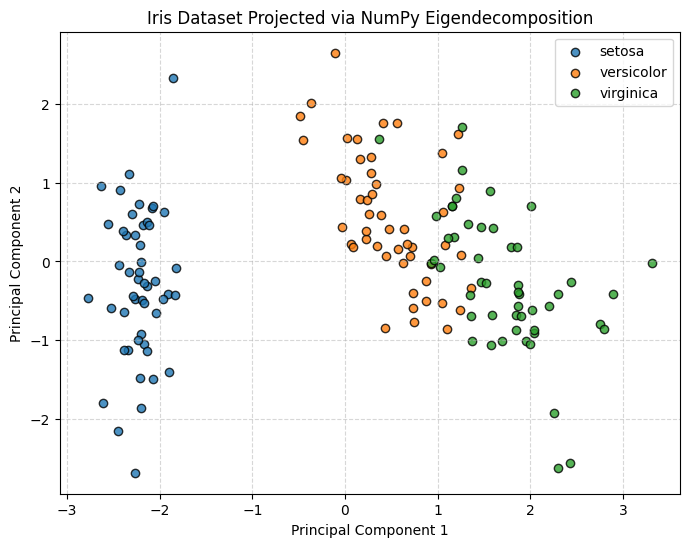

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# 1. Load and scale the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

X_scaled = StandardScaler().fit_transform(X)

# 2. Get eigenvalues & eigenvectors from Covariance Matrix
cov_matrix = np.cov(X_scaled, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Sort eigenvectors by eigenvalues (descending order)
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvectors = eigenvectors[:, sorted_indices]

# 3. Project the scaled data onto the first 2 principal components
# Using the dot product: Matrix multiplication of (150, 4) x (4, 2) -> (150, 2)
X_pca = X_scaled.dot(eigenvectors[:, :5])

# 4. Create the scatter plot using plt
plt.figure(figsize=(8, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Distinct colors for the 3 classes

for i, color, target_name in zip([0, 1, 2], colors, target_names):
    plt.scatter(
        X_pca[y == i, 0], 
        X_pca[y == i, 1], 
        color=color, 
        alpha=0.8, 
        edgecolors='k', 
        label=target_name
    )

# Formatting the chart
plt.title('Iris Dataset Projected via NumPy Eigendecomposition')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)

# Display the plot
plt.show()